# Learning Curve 2b: What's next

**Marko Antolčić · NeuralGambit research**

The plateau study predicted one thing: will a player gain **+75** over the next 100 games? It learned from the first 700 games of 581 new players. This notebook replaces it with a model that answers the whole question, from all the game data the two Lichess studies collected:

- **Where am I now?** Climbing, on a plateau or sliding over the last 100 games (the window rule from the plateau study, unchanged).
- **What comes next?** The chance to **climb** (+75 or more), **hold** (within ±75) or **drop** (−75 or more) over the next 100 games.

It runs on the [NeuralGambit Learning Curve tab](https://www.neuralgambit.com/stats/learning-curve).

## Data

- **Players.** The 1,117 players of the 2000 study (accounts created July 2020 – January 2021; every player who later reached 2000 and a random sample of the rest), plus the 502 players of the plateau study who are not among them.
- **Games.** Whole careers for players followed to the end; for players who reached 2000, up to the 30-day hold at 2000+ and then up to 3,000 more games; up to game 1,000 for the rest of the 2000 study; the first 700 games for the plateau study (`pipeline/s12_trend_windows.py`).
- **Windows.** Each history is cut into 100-game windows sliding by 25 games, after the first 30 (provisional) games. Each window has the 17 features of the plateau study and the rating change over the next 100 games (mean of the last 10 ratings, then and now).
- **Weights.** Players who didn't reach 2000 were sampled about 1 in 9 in the 2000 study, so each counts about 8.7 times. A player's windows share at most 200 windows' worth of weight, so a few players with 20,000+ games don't dominate.

**Why windows from whole careers, and not only the last games?** A study player's last games have no "next 100 games" to learn from, and keeping only late windows would throw most of the data away. The model learns from every point of every career, with the career stage (games played so far) as an input, and its accuracy is checked separately on late careers and on each player's last window.

In [1]:
import sys, json, shutil, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

from pipeline.common import DATA, OUT
from pipeline.features import FEATURES, FLAT_TREND, WINDOW
from pipeline.s12_trend_windows import CLIMB, DROP

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
FIG = OUT / "fig"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
GREEN, GOLD, RED, GREY = "#629924", "#d69e2e", "#e53e3e", "#8a8f98"
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

w = pd.read_parquet(DATA / "windows_all.parquet")
w["time_use"] = w["time_use"].fillna(w["time_use"].median())
w["W"] = w.weight * w.w_cap
CL = ["climb", "hold", "drop"]
y = w.outcome.map({c: i for i, c in enumerate(CL)}).to_numpy()
W = w.W.to_numpy()
BANDS = [0, 1200, 1400, 1600, 1800, 2000, 3500]
LABELS = ["<1200", "1200–1400", "1400–1600", "1600–1800", "1800–2000", "2000+"]
w["band"] = pd.cut(w.rating, BANDS, labels=LABELS, right=False)
w["stage"] = pd.cut(w.career_games, [0, 300, 700, 1500, 3000, 1e6], labels=["<300", "300–700", "700–1,500", "1,500–3,000", "3,000+"])
print(f"{w.player.nunique():,} players, {len(w):,} windows "
      f"({(w.source == '2000 study').sum():,} from the 2000 study, {(w.source == 'plateau study').sum():,} from the plateau study)")

1,554 players, 123,662 windows (114,864 from the 2000 study, 8,798 from the plateau study)


## 1. What usually happens next

Weighted shares of the three outcomes, by rating and by career stage.

,windows,players,climb,hold,drop
band,,,,,
<1200,"9,064",548,17.6%,78.6%,3.8%
1200–1400,"6,768",526,13.6%,81.6%,4.8%
1400–1600,"7,474",524,10.5%,84.1%,5.3%
1600–1800,"16,094",523,9.5%,85.8%,4.7%
1800–2000,"61,464",490,5.9%,89.0%,5.2%
2000+,"22,798",374,3.1%,88.3%,8.6%


,windows,players,climb,hold,drop
stage,,,,,
<300,"10,630","1,554",16.0%,79.9%,4.1%
300–700,"20,112","1,464",11.9%,83.3%,4.8%
"700–1,500","14,530",867,10.0%,84.3%,5.7%
"1,500–3,000","16,800",306,7.3%,87.1%,5.6%
"3,000+","61,590",247,5.8%,88.9%,5.3%


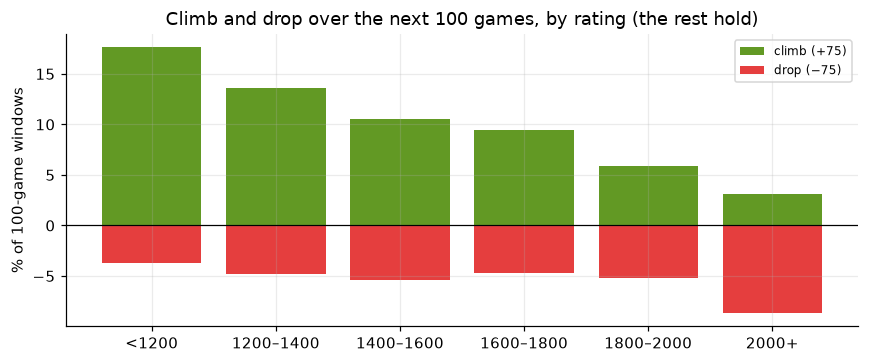

In [2]:
def rates(d):
    return pd.Series({"windows": len(d), "players": d.player.nunique(),
                      **{o: np.average(d.outcome == o, weights=d.W) for o in CL}})
by_band = w.groupby("band", observed=True).apply(rates)
by_stage = w.groupby("stage", observed=True).apply(rates)
display(by_band.style.format({"windows": "{:,.0f}", "players": "{:,.0f}", **{o: "{:.1%}" for o in CL}}))
display(by_stage.style.format({"windows": "{:,.0f}", "players": "{:,.0f}", **{o: "{:.1%}" for o in CL}}))

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(by_band))
ax.bar(x, by_band["climb"] * 100, color=GREEN, label="climb (+75)")
ax.bar(x, -by_band["drop"] * 100, color=RED, label="drop (−75)")
ax.axhline(0, color="black", lw=.8)
ax.set_xticks(x, by_band.index)
ax.set(ylabel="% of 100-game windows", title="Climb and drop over the next 100 games, by rating (the rest hold)")
ax.legend(fontsize=8)
save("next100-by-band")

**Reading the result.**

- **Holding is the norm.** Over 100 games, about 84% of windows stay within ±75 of where they started.
- **Climbs get rarer as the rating rises:** about 18% below 1200, about 6% at 1800–2000, about 3% at 2000+. They also get rarer with experience.
- **Drops are rare and similar everywhere (4–5%) except at 2000+ (about 9%).** This isn't only players who touched 2000 and fell back. After their 30-day hold, players who reached 2000 still dropped 75 points in about 8% of windows (11,191 windows, 236 players). Players who touched 2000 but never held it dropped in about 13%. The ups and downs above 2000 are wider than below.

### Life after 2000

Players who reached 2000 were first downloaded only until they held it for 30 days. To see what happens next, each of the 338 was then followed for up to 3,000 more games (about 525,000 games, `pipeline/s09_later_games.py --after-hold`). The windows at 2000+ can be split three ways: before the hold, after the hold, and players who touched 2000 but never held it.

,windows,players,climb,hold,drop
zone,,,,,
before the hold,"8,395",244,2.4%,89.2%,8.4%
after the hold,"11,191",236,3.5%,88.6%,7.8%
"touched 2000, never held","3,212",100,2.7%,84.7%,12.6%


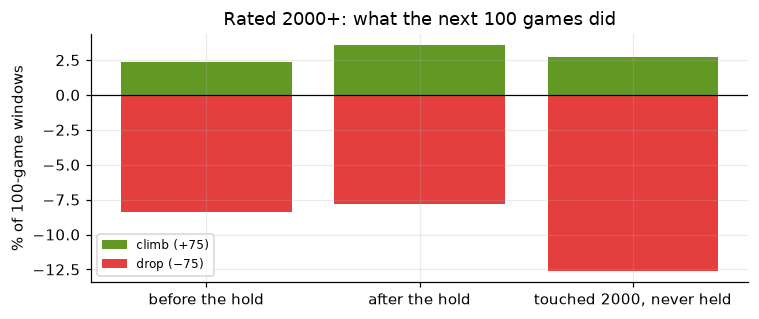

In [3]:
full = pd.read_parquet(DATA / "full.parquet", columns=["player", "idx", "after_hold"])
full["player"] = full.player.astype(str)
first_after = full[full.after_hold].groupby("player").idx.min()
del full
hi = w[w.rating >= 2000].copy()
fa = hi.player.astype(str).map(first_after)
hi["zone"] = np.select([fa.isna(), hi.end >= fa], ["touched 2000, never held", "after the hold"], "before the hold")
by_zone = hi.groupby("zone").apply(rates).loc[["before the hold", "after the hold", "touched 2000, never held"]]
display(by_zone.style.format({"windows": "{:,.0f}", "players": "{:,.0f}", **{o: "{:.1%}" for o in CL}}))

fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(by_zone))
ax.bar(x, by_zone["climb"] * 100, color=GREEN, label="climb (+75)")
ax.bar(x, -by_zone["drop"] * 100, color=RED, label="drop (−75)")
ax.axhline(0, color="black", lw=.8)
ax.set_xticks(x, by_zone.index)
ax.set(ylabel="% of 100-game windows", title="Rated 2000+: what the next 100 games did")
ax.legend(fontsize=8)
save("next100-after-2000")

**Reading the result.** After the hold, about 8% of 100-game stretches still dropped 75 points, compared with 4–5% below 2000. Players who touched 2000 but never held it dropped more often (about 13%). Above 2000 the rating simply swings more: opponents are stronger and closer in level, and the players are near their best.

## 2. Predicting the next 100 games

Three models, each predicting the chance of climb, hold and drop, compared with **5-fold cross-validation grouped by player** (no player is in both the training and the test fold):

- **Rating only:** a flexible (spline) curve of the current rating, the baseline.
- **All 17 features, logistic:** multinomial logistic regression.
- **All 17 features, gradient boosting:** 150 shallow trees per outcome, which can capture thresholds and interactions.

Measures: **AUC** for climb vs the rest and for drop vs the rest (0.5 = coin flip, 1 = perfect ranking), and **log loss** for the three probabilities together (lower is better). All weighted as above.

In [4]:
def gbm():
    return GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.5,
                                      min_samples_leaf=100, random_state=0)

MODELS = {
    "rating only": (["rating"], lambda: make_pipeline(SplineTransformer(n_knots=6), LogisticRegression(max_iter=2000)), "logisticregression__"),
    "all features, logistic": (FEATURES, lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), "logisticregression__"),
    "all features, gradient boosting": (FEATURES, gbm, ""),
}
OOF = {}
for name, (cols, make, prefix) in MODELS.items():
    oof = np.zeros((len(w), 3))
    for tr, te in GroupKFold(5).split(w, y, w.player):
        m = make().fit(w.iloc[tr][cols], y[tr], **{f"{prefix}sample_weight": W[tr]})
        oof[te] = m.predict_proba(w.iloc[te][cols])
    OOF[name] = oof

last = (w.groupby("player").end.transform("max") == w.end).to_numpy()
SUBSETS = {"all windows": np.ones(len(w), bool), "on a plateau now": w.flat.to_numpy(), "rating 2000+": (w.rating >= 2000).to_numpy(),
           "career 1,500+ games": (w.career_games >= 1500).to_numpy(), "each player's last window": last}
rows = []
for name, p in OOF.items():
    for s, m in SUBSETS.items():
        rows.append({"subset": s, "model": name, "windows": int(m.sum()),
                     "AUC climb": roc_auc_score(y[m] == 0, p[m, 0], sample_weight=W[m]),
                     "AUC drop": roc_auc_score(y[m] == 2, p[m, 2], sample_weight=W[m]),
                     "log loss": log_loss(y[m], p[m], sample_weight=W[m], labels=[0, 1, 2])})
CV = pd.DataFrame(rows).set_index(["subset", "model"])
CV.round(3)

,,windows,AUC climb,AUC drop,log loss
subset,model,,,,
all windows,rating only,123662,0.642,0.551,0.520
on a plateau now,rating only,50704,0.653,0.553,0.480
rating 2000+,rating only,22798,0.496,0.509,0.430
"career 1,500+ games",rating only,78390,0.663,0.593,0.429
each player's last window,rating only,1554,0.553,0.579,0.664
all windows,"all features, logistic",123662,0.669,0.620,0.513
on a plateau now,"all features, logistic",50704,0.671,0.617,0.474
rating 2000+,"all features, logistic",22798,0.626,0.643,0.419
"career 1,500+ games","all features, logistic",78390,0.669,0.627,0.423


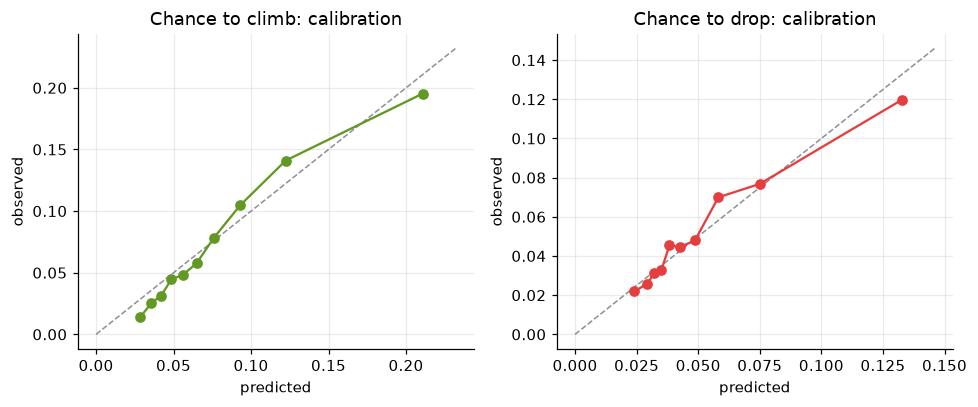

In [5]:
P = OOF["all features, gradient boosting"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, k, col in [(axes[0], 0, GREEN), (axes[1], 2, RED)]:
    b = pd.qcut(P[:, k], 10, duplicates="drop")
    d = pd.DataFrame({"b": b, "p": P[:, k], "o": y == k, "W": W}).groupby("b", observed=True).apply(
        lambda d: pd.Series({"pred": np.average(d.p, weights=d.W), "obs": np.average(d.o, weights=d.W)}))
    hi = max(d.pred.max(), d.obs.max()) * 1.1
    ax.plot([0, hi], [0, hi], color=GREY, ls="--", lw=1)
    ax.plot(d.pred, d.obs, "o-", color=col)
    ax.set(xlabel="predicted", ylabel="observed", title=f"Chance to {CL[k]}: calibration")
save("next100-calibration")

**Reading the result.**

- **Gradient boosting is the best of the three** for both climbs (AUC about 0.69) and drops (about 0.65). The old +75 model reached 0.63 on its own data. Rating alone barely predicts drops (0.55).
- **It holds up where the dashboard needs it:** in long careers (1,500+ games) and at 2000+ it does as well or better than overall. On each player's very last window it is weaker for climbs; those windows are often the stretch right before a player stopped.
- **The probabilities are honest.** Grouped into tenths, the predicted and observed chances lie close to the diagonal, so a predicted 20% climb meant about 20 in 100 climbed.
- **Still modest.** Most of the next 100 games is noise: the model shifts the odds, it can't say what will happen.

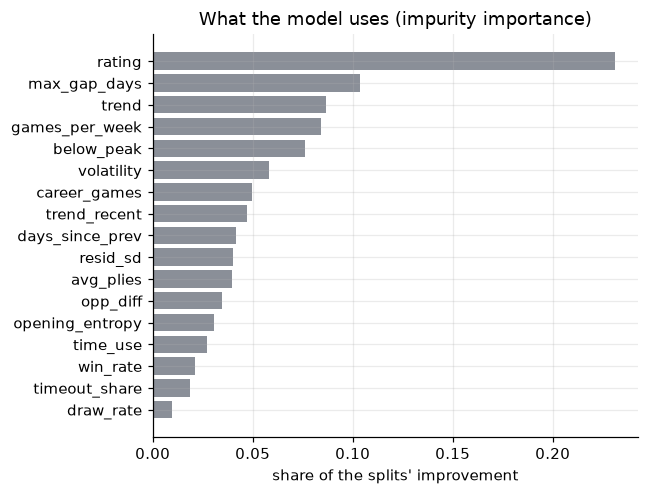

In [6]:
final = gbm().fit(w[FEATURES], y, sample_weight=W)
imp = pd.Series(final.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.barh(imp.index, imp.values, color=GREY)
ax.set(title="What the model uses (impurity importance)", xlabel="share of the splits' improvement")
save("next100-importance")

**What the model uses.** The importance chart shows which inputs the trees split on most. It says what *predicts*, not what *causes*: the rating, how far below the player's best they are, the trend and the career stage carry most of the weight, as in the plateau study.

## 3. What moves a player's chances

The importance chart says which inputs the model uses, not in which direction. Two views help a reader:

- **What the data shows:** the observed drop and climb rates by how often a player plays, by the longest break inside their last 100 games, and by their share of games decided on time. No model, only weighted counts.
- **What the model says for one player:** take one player's inputs and swap one at a time for the typical value, then see how the chances move. This is how the dashboard could explain a high or low chance.

Both are associations: a player who starts playing more often isn't guaranteed to drop less.

,windows,players,climb,drop
b,,,,
<5,"2,441",435,20.4%,12.5%
5–15,"5,053",671,17.5%,8.3%
15–30,"8,405",904,14.7%,4.6%
30–60,"18,410","1,206",12.6%,4.4%
60+,"89,353","1,302",8.2%,4.5%


,windows,players,climb,drop
b,,,,
<3 days,"99,148","1,465",9.0%,4.5%
3–14 days,"17,906","1,105",14.2%,5.0%
2–8 weeks,"4,436",562,18.2%,8.2%
2–6 months,"1,397",306,18.9%,12.2%
6+ months,775,190,20.9%,15.3%


,windows,players,climb,drop
b,,,,
<5%,759,173,19.6%,2.2%
5–10%,"6,502",641,14.6%,4.2%
10–20%,"40,333","1,266",11.0%,5.2%
20%+,"76,068","1,240",9.7%,5.0%


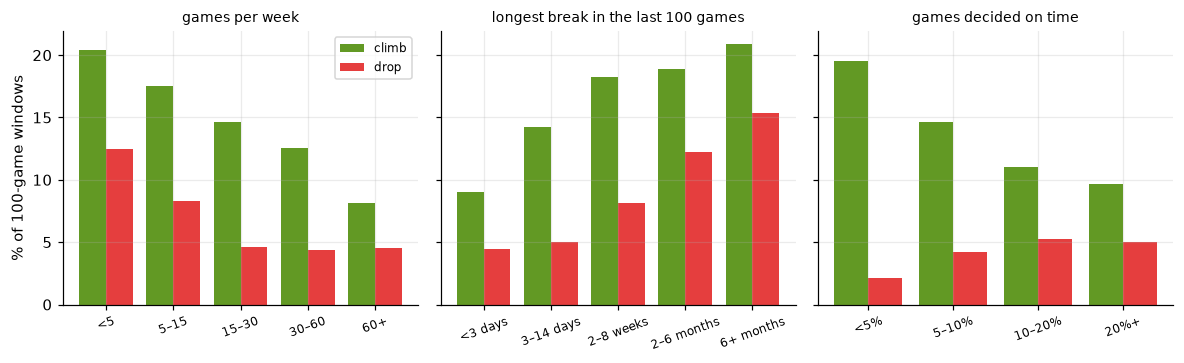

In [7]:
def binned(col, edges, labels):
    d = w.assign(b=pd.cut(w[col], edges, labels=labels, right=False))
    return d.groupby("b", observed=True).apply(rates)[["windows", "players", "climb", "drop"]]

HABITS = {
    "games_per_week": ([0, 5, 15, 30, 60, 1e9], ["<5", "5–15", "15–30", "30–60", "60+"], "games per week"),
    "max_gap_days": ([0, 3, 14, 60, 180, 1e9], ["<3 days", "3–14 days", "2–8 weeks", "2–6 months", "6+ months"], "longest break in the last 100 games"),
    "timeout_share": ([0, .05, .10, .20, 1.01], ["<5%", "5–10%", "10–20%", "20%+"], "games decided on time"),
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (col, (edges, labels, title)) in zip(axes, HABITS.items()):
    t = binned(col, edges, labels)
    display(t.style.set_caption(title).format({"windows": "{:,.0f}", "players": "{:,.0f}", "climb": "{:.1%}", "drop": "{:.1%}"}))
    x = np.arange(len(t))
    ax.bar(x - .2, t["climb"] * 100, .4, color=GREEN, label="climb")
    ax.bar(x + .2, t["drop"] * 100, .4, color=RED, label="drop")
    ax.set_xticks(x, t.index, rotation=20, fontsize=8); ax.set_title(title, fontsize=9)
axes[0].set_ylabel("% of 100-game windows"); axes[0].legend(fontsize=8)
save("next100-habits")

**A worked example.** A player rated 2,040 who climbed +54 over their last 100 games, plays about 2 games a week and took a 299-day break inside those 100 games. Each row swaps one input for the typical value and shows the new chances.

In [8]:
example = {"rating": 2040, "trend": 54.3, "trend_recent": 25.8, "volatility": 8.5, "resid_sd": 10.5, "win_rate": .57, "draw_rate": .02,
           "opp_diff": -8.4, "games_per_week": 2.2, "max_gap_days": 298.8, "days_since_prev": 3.1, "below_peak": 17,
           "career_games": 1400, "opening_entropy": 3.39, "avg_plies": 74.2, "timeout_share": .22, "time_use": .62}
typical = w[FEATURES].median()
SWAPS = {"(their own games)": {}, "no long break": {"max_gap_days": typical.max_gap_days},
         "typical pace": {"games_per_week": typical.games_per_week}, "flat trend instead of the climb": {"trend": 0, "trend_recent": 0},
         "typical share of games decided on time": {"timeout_share": typical.timeout_share},
         "no break and typical pace": {"max_gap_days": typical.max_gap_days, "games_per_week": typical.games_per_week}}
X = pd.DataFrame([{**example, **ch} for ch in SWAPS.values()], index=list(SWAPS))[FEATURES]
pd.DataFrame(final.predict_proba(X), index=X.index, columns=CL).style.format("{:.0%}")

,climb,hold,drop
(their own games),5%,57%,38%
no long break,4%,68%,28%
typical pace,4%,69%,27%
flat trend instead of the climb,6%,61%,34%
typical share of games decided on time,5%,57%,38%
no break and typical pace,3%,78%,18%


In [9]:
near = w[(w.rating >= 1950) & (w.games_per_week < 5) & (w.max_gap_days > 100) & (w.trend > 30)]
print(f"Players at 1950+ playing under 5 games a week, with a 100+ day break and a recent climb: "
      f"{len(near):,} windows, {near.player.nunique()} players, drop in {np.average(near.outcome == 'drop', weights=near.W):.0%}")

Players at 1950+ playing under 5 games a week, with a 100+ day break and a recent climb: 196 windows, 85 players, drop in 30%


**Reading the result.**

- **Breaks and a slow pace go with bigger swings.** Players who play rarely or come back from a long break drop more often, and also climb more often: their rating has had time to fall out of step with their strength.
- **For the example player**, the long break and the slow pace together explain most of the higher drop chance. Players in the data with the same pattern did drop often (the count above), so the high number isn't a quirk of the model.

## 4. Export for the NeuralGambit dashboard

`next100.json` holds the trees (three sets, one per outcome, combined with a softmax), the typical shares by rating band (shown next to the player's own chances) and the rating range the model saw. A check confirms the exported trees give the same probabilities as scikit-learn.

In [10]:
def tree_arrays(est):
    t = est.tree_
    return {"f": t.feature.tolist(), "t": np.round(t.threshold, 6).tolist(), "l": t.children_left.tolist(),
            "r": t.children_right.tolist(), "v": np.round(t.value[:, 0, 0], 6).tolist()}

init = final._raw_predict_init(w[FEATURES].iloc[:1].to_numpy(dtype=np.float32))[0]
spec = {"features": FEATURES, "classes": CL, "lr": final.learning_rate, "init": [round(float(v), 6) for v in init],
        "trees": [[tree_arrays(final.estimators_[i, k]) for i in range(final.n_estimators_)] for k in range(3)]}

def predict_spec(spec, X):
    out = []
    for row in X[spec["features"]].to_numpy(dtype=np.float32):
        z = list(spec["init"])
        for k, trees in enumerate(spec["trees"]):
            for t in trees:
                n = 0
                while t["l"][n] != -1:
                    n = t["l"][n] if row[t["f"][n]] <= t["t"][n] else t["r"][n]
                z[k] += spec["lr"] * t["v"][n]
        e = np.exp(np.array(z) - max(z)); out.append(e / e.sum())
    return np.array(out)

check = w.sample(400, random_state=1)
diff = np.abs(predict_spec(spec, check) - final.predict_proba(check[FEATURES])).max()
print(f"max difference between exported model and sklearn: {diff:.1e}")

gb = CV.xs("all features, gradient boosting", level="model")
spec["meta"] = {"climb": CLIMB, "drop": DROP, "window": WINDOW, "flat_trend": FLAT_TREND,
                "players": int(w.player.nunique()), "windows": int(len(w)),
                "auc_climb": round(float(gb.loc["all windows", "AUC climb"]), 3), "auc_drop": round(float(gb.loc["all windows", "AUC drop"]), 3),
                "rating_range": [int(round(v, -1)) for v in np.percentile(w.rating, [1, 99])]}
spec["bands"] = [{"band": str(b), "lo": lo, **{o: round(float(r[o]), 4) for o in CL},
                  **{f"{o}_flat": round(float(np.average(w[(w.band == b) & w.flat].outcome == o, weights=w[(w.band == b) & w.flat].W)), 4) for o in CL}}
                 for (b, r), lo in zip(by_band.iterrows(), BANDS)]
spec["time_use_median"] = round(float(w.time_use.median()), 4)
(OUT / "next100.json").write_text(json.dumps(spec, separators=(",", ":")))
APP_STATIC = ROOT.parents[1] / "static" / "plateau"
shutil.copy(OUT / "next100.json", APP_STATIC / "next100.json")
print("wrote", OUT / "next100.json", f"({(OUT / 'next100.json').stat().st_size / 1024:.0f} KB), copied to", APP_STATIC)

max difference between exported model and sklearn: 1.4e-07


wrote C:\Users\marko\PycharmProjects\Chessmatics\research\plateau\out\next100.json (153 KB), copied to C:\Users\marko\PycharmProjects\Chessmatics\static\plateau


## 5. How the Learning Curve tab shows it

The tab ([NeuralGambit Learning Curve](https://www.neuralgambit.com/stats/learning-curve)) reads a player's last rated blitz games from Lichess (or chess.com, converted to the Lichess scale) and computes the same 17 inputs in the browser (`static/js/plateau.js`, a copy of `pipeline/features.py`).

| On the page | Rule |
|---|---|
| **Right now:** climbing, on a plateau or sliding | the trend line over the last 100 games; a plateau is within ±30 |
| **Your next 100 games:** three bars | the model's chance to climb (+75), hold or drop (−75) |
| Thin mark on each bar | the usual share for the player's rating band (section 1); the plateau-only share if they are on a plateau |
| "better than usual" / "higher than usual" | the player's climb or drop chance is more than 1.3 times the usual one |
| "take this as a rough guess" | rating outside the range the model learned from (1st–99th percentile, about 900–2,170) |
| "describes that period, not today" | the latest game is more than 90 days old |
| "Too early" | fewer than 102 rated blitz games |

Who sees what: players below 2000 see this section under their learning curve and their chance of reaching 2000. Players rated 2000+ now, or who already held 2000 for 30 days, see only this section.

## Summary

- **Where you are now** is the plateau study's window rule: the trend line over the last 100 games, flat within ±30.
- **What comes next** is three chances, climb (+75), hold or drop (−75) over the next 100 games, from a gradient-boosted model trained on about 124,000 windows from 1,550 players' careers. It ranks climbs and drops better than the rating alone and its probabilities are well calibrated, but most of what happens over 100 games stays unpredictable.
- **What moves it:** a slow pace and long breaks go with bigger swings both ways; above 2000 drops are about twice as common as below.
- **Limits.** One cohort of accounts from late 2020, blitz only. Life after 2000 comes from the 338 players who held it, each followed up to 3,000 games past the hold (about 525,000 games); the model saw ratings up to about 2,170, so higher ratings are outside its range.